In [7]:
%pip install -U matplotlib

Looking in indexes: http://mirrors.aliyun.com/pypi/simple
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.8/8.8 MB 826.9 kB/s  0:00:10m0:00:0100:01
  Attempting uninstall: matplotlib
    Found existing installation: matplotlib 3.6.3
    Uninstalling matplotlib-3.6.3:
      Successfully uninstalled matplotlib-3.6.3
Note: you may need to restart the kernel to use updated packages.


In [1]:
from pathlib import Path

PROJECT_DIR = Path("/root/autodl-tmp/shift_aware_uav")
PROJECT_DIR.mkdir(parents=True, exist_ok=True)

DATA_YAML = PROJECT_DIR / "visdrone.yaml"

yaml_content = """
path: /root/autodl-tmp/shift_aware_uav/data/visdrone_yolo
train: images/train
val: images/val

names:
  0: pedestrian
  1: people
  2: bicycle
  3: car
  4: van
  5: truck
  6: tricycle
  7: awning-tricycle
  8: bus
  9: motor
""".strip()

DATA_YAML.write_text(yaml_content)

print("YAML 路径：", DATA_YAML)
print("文件存在：", DATA_YAML.exists())
print(DATA_YAML.read_text())

YAML 路径： /root/autodl-tmp/shift_aware_uav/visdrone.yaml
文件存在： True
path: /root/autodl-tmp/shift_aware_uav/data/visdrone_yolo
train: images/train
val: images/val

names:
  0: pedestrian
  1: people
  2: bicycle
  3: car
  4: van
  5: truck
  6: tricycle
  7: awning-tricycle
  8: bus
  9: motor


In [2]:
import os
from ultralytics import YOLO

PROJECT_DIR = "/root/autodl-tmp/shift_aware_uav"
os.environ["YOLO_CONFIG_DIR"] = f"{PROJECT_DIR}/yolo_config"

DATA_YAML = f"{PROJECT_DIR}/visdrone.yaml"
RUNS_DIR = f"{PROJECT_DIR}/runs"

model = YOLO("yolo11n.pt")

In [3]:
results = model.train(
    data=DATA_YAML,
    epochs=1,
    imgsz=640,
    batch=16,
    device=0,
    workers=8,
    pretrained=True,
    optimizer="auto",
    patience=15,
    seed=42,
    project=RUNS_DIR,
    name="visdrone_source_check",
    exist_ok=True,
)

New https://pypi.org/project/ultralytics/8.4.165 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.159 🚀 Python-3.10.8 torch-2.7.1+cu118 CUDA:0 (NVIDIA GeForce RTX 3090, 24124MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/root/autodl-tmp/shift_aware_uav/visdrone.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=1, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0

curl: (28) Connection timeout after 30001 ms       #     #    #   #           
curl: (28) Connection timeout after 30000 ms      #    #     #   #            
curl: (28) Connection timeout after 30001 ms                                  
curl: (28) Connection timeout after 30000 ms    #    #     #                  


WARNING ⚠️ Download failure, retrying 2/3 https://github.com/ultralytics/assets/releases/download/v8.4.0/yolo26n.pt... Curl return value 28


curl: (28) Connection timeout after 30001 ms               #   #    #  #      

######################################################################## 100.0%


AMP: checks passed ✅
train: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3545.8±889.2 MB/s, size: 461.4 KB)
train: Scanning /root/autodl-tmp/shift_aware_uav/data/visdrone_yolo/labels/train... 6471 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 6471/6471 1.6Kit/s 4.1s0.0s
train: /root/autodl-tmp/shift_aware_uav/data/visdrone_yolo/images/train/0000137_02220_d_0000163.jpg: 1 duplicate labels removed
train: /root/autodl-tmp/shift_aware_uav/data/visdrone_yolo/images/train/0000140_00118_d_0000002.jpg: 1 duplicate labels removed
train: /root/autodl-tmp/shift_aware_uav/data/visdrone_yolo/images/train/9999945_00000_d_0000114.jpg: 1 duplicate labels removed
train: /root/autodl-tmp/shift_aware_uav/data/visdrone_yolo/images/train/9999987_00000_d_0000049.jpg: 1 duplicate labels removed
train: New cache created: /root/autodl-tmp/shift_aware_uav/data/visdrone_yolo/labels/train.cache
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2747.9±456.5 MB/s, size: 210.7 KB)
val: Scanning /root/autodl-tm

# Baseline

In [4]:
model = YOLO("yolo11n.pt")

results = model.train(
    data=DATA_YAML,
    epochs=50,
    imgsz=640,
    batch=16,
    device=0,
    workers=8,
    pretrained=True,
    optimizer="auto",
    patience=15,
    seed=42,
    project=RUNS_DIR,
    name="visdrone_source_yolo11n",
    exist_ok=True,
)

New https://pypi.org/project/ultralytics/8.4.165 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.159 🚀 Python-3.10.8 torch-2.7.1+cu118 CUDA:0 (NVIDIA GeForce RTX 3090, 24124MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/root/autodl-tmp/shift_aware_uav/visdrone.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=

# 分布偏移

## 生成分布偏移的数据集

In [20]:
from pathlib import Path
import shutil
import cv2
import numpy as np

PROJECT_DIR = Path("/root/autodl-tmp/shift_aware_uav")
SOURCE_IMG_DIR = PROJECT_DIR / "data/visdrone_yolo/images/val"
SOURCE_LABEL_DIR = PROJECT_DIR / "data/visdrone_yolo/labels/val"

WEATHER_ROOT = PROJECT_DIR / "data/weather_shift"

def make_fog(image):
    """中等强度雾天：降低对比度并叠加白色雾层。"""
    h, w = image.shape[:2]
    haze = np.full_like(image, 235)
    fog = cv2.addWeighted(image, 0.42, haze, 0.58, 0)
    fog = cv2.GaussianBlur(fog, (0, 0), sigmaX=1.2)
    return fog

def make_rain(image, rng,severity="heavy"):
    """中等强度雨天：降低亮度并叠加模糊雨丝。"""
    settings = {
        "medium": {"darken": 0.75, "count": 550,  "length": (15, 30), "width": 1, "alpha": 0.65},
        "heavy":  {"darken": 0.62, "count": 1200, "length": (25, 50), "width": 2, "alpha": 0.85},
    }
    cfg = settings[severity]

    h, w = image.shape[:2]
    rainy = (image.astype(np.float32) * cfg["darken"]).astype(np.uint8)
    layer = np.zeros_like(image)

    # 分辨率越大，雨丝数量也相应增加
    n_streaks = max(cfg["count"], (h * w) // 900)

    for _ in range(n_streaks):
        x = int(rng.integers(0, w))
        y = int(rng.integers(0, h))
        length = int(rng.integers(*cfg["length"]))

        # 略微倾斜的雨丝
        cv2.line(
            layer,
            (x, y),
            (max(0, x - length // 5), min(h - 1, y + length)),
            (220, 220, 220),
            cfg["width"],
        )

    layer = cv2.GaussianBlur(layer, (3, 3), 0)
    return cv2.addWeighted(rainy, 1.0, layer, cfg["alpha"], 0)

def build_weather_split(weather_name, transform, seed=42):
    image_out = WEATHER_ROOT / weather_name / "images/val"
    label_out = WEATHER_ROOT / weather_name / "labels/val"
    image_out.mkdir(parents=True, exist_ok=True)
    label_out.mkdir(parents=True, exist_ok=True)

    rng = np.random.default_rng(seed)

    for image_path in sorted(SOURCE_IMG_DIR.glob("*.jpg")):
        image = cv2.imread(str(image_path))
        if image is None:
            raise RuntimeError(f"无法读取: {image_path}")

        transformed = transform(image, rng) if weather_name == "rain" else transform(image)
        cv2.imwrite(str(image_out / image_path.name), transformed)

        label_path = SOURCE_LABEL_DIR / f"{image_path.stem}.txt"
        shutil.copy2(label_path, label_out / label_path.name)

    print(f"{weather_name}: 已生成 {len(list(image_out.glob('*.jpg')))} 张图像")

build_weather_split("fog", make_fog)
build_weather_split("rain", make_rain)

fog: 已生成 548 张图像
rain: 已生成 548 张图像


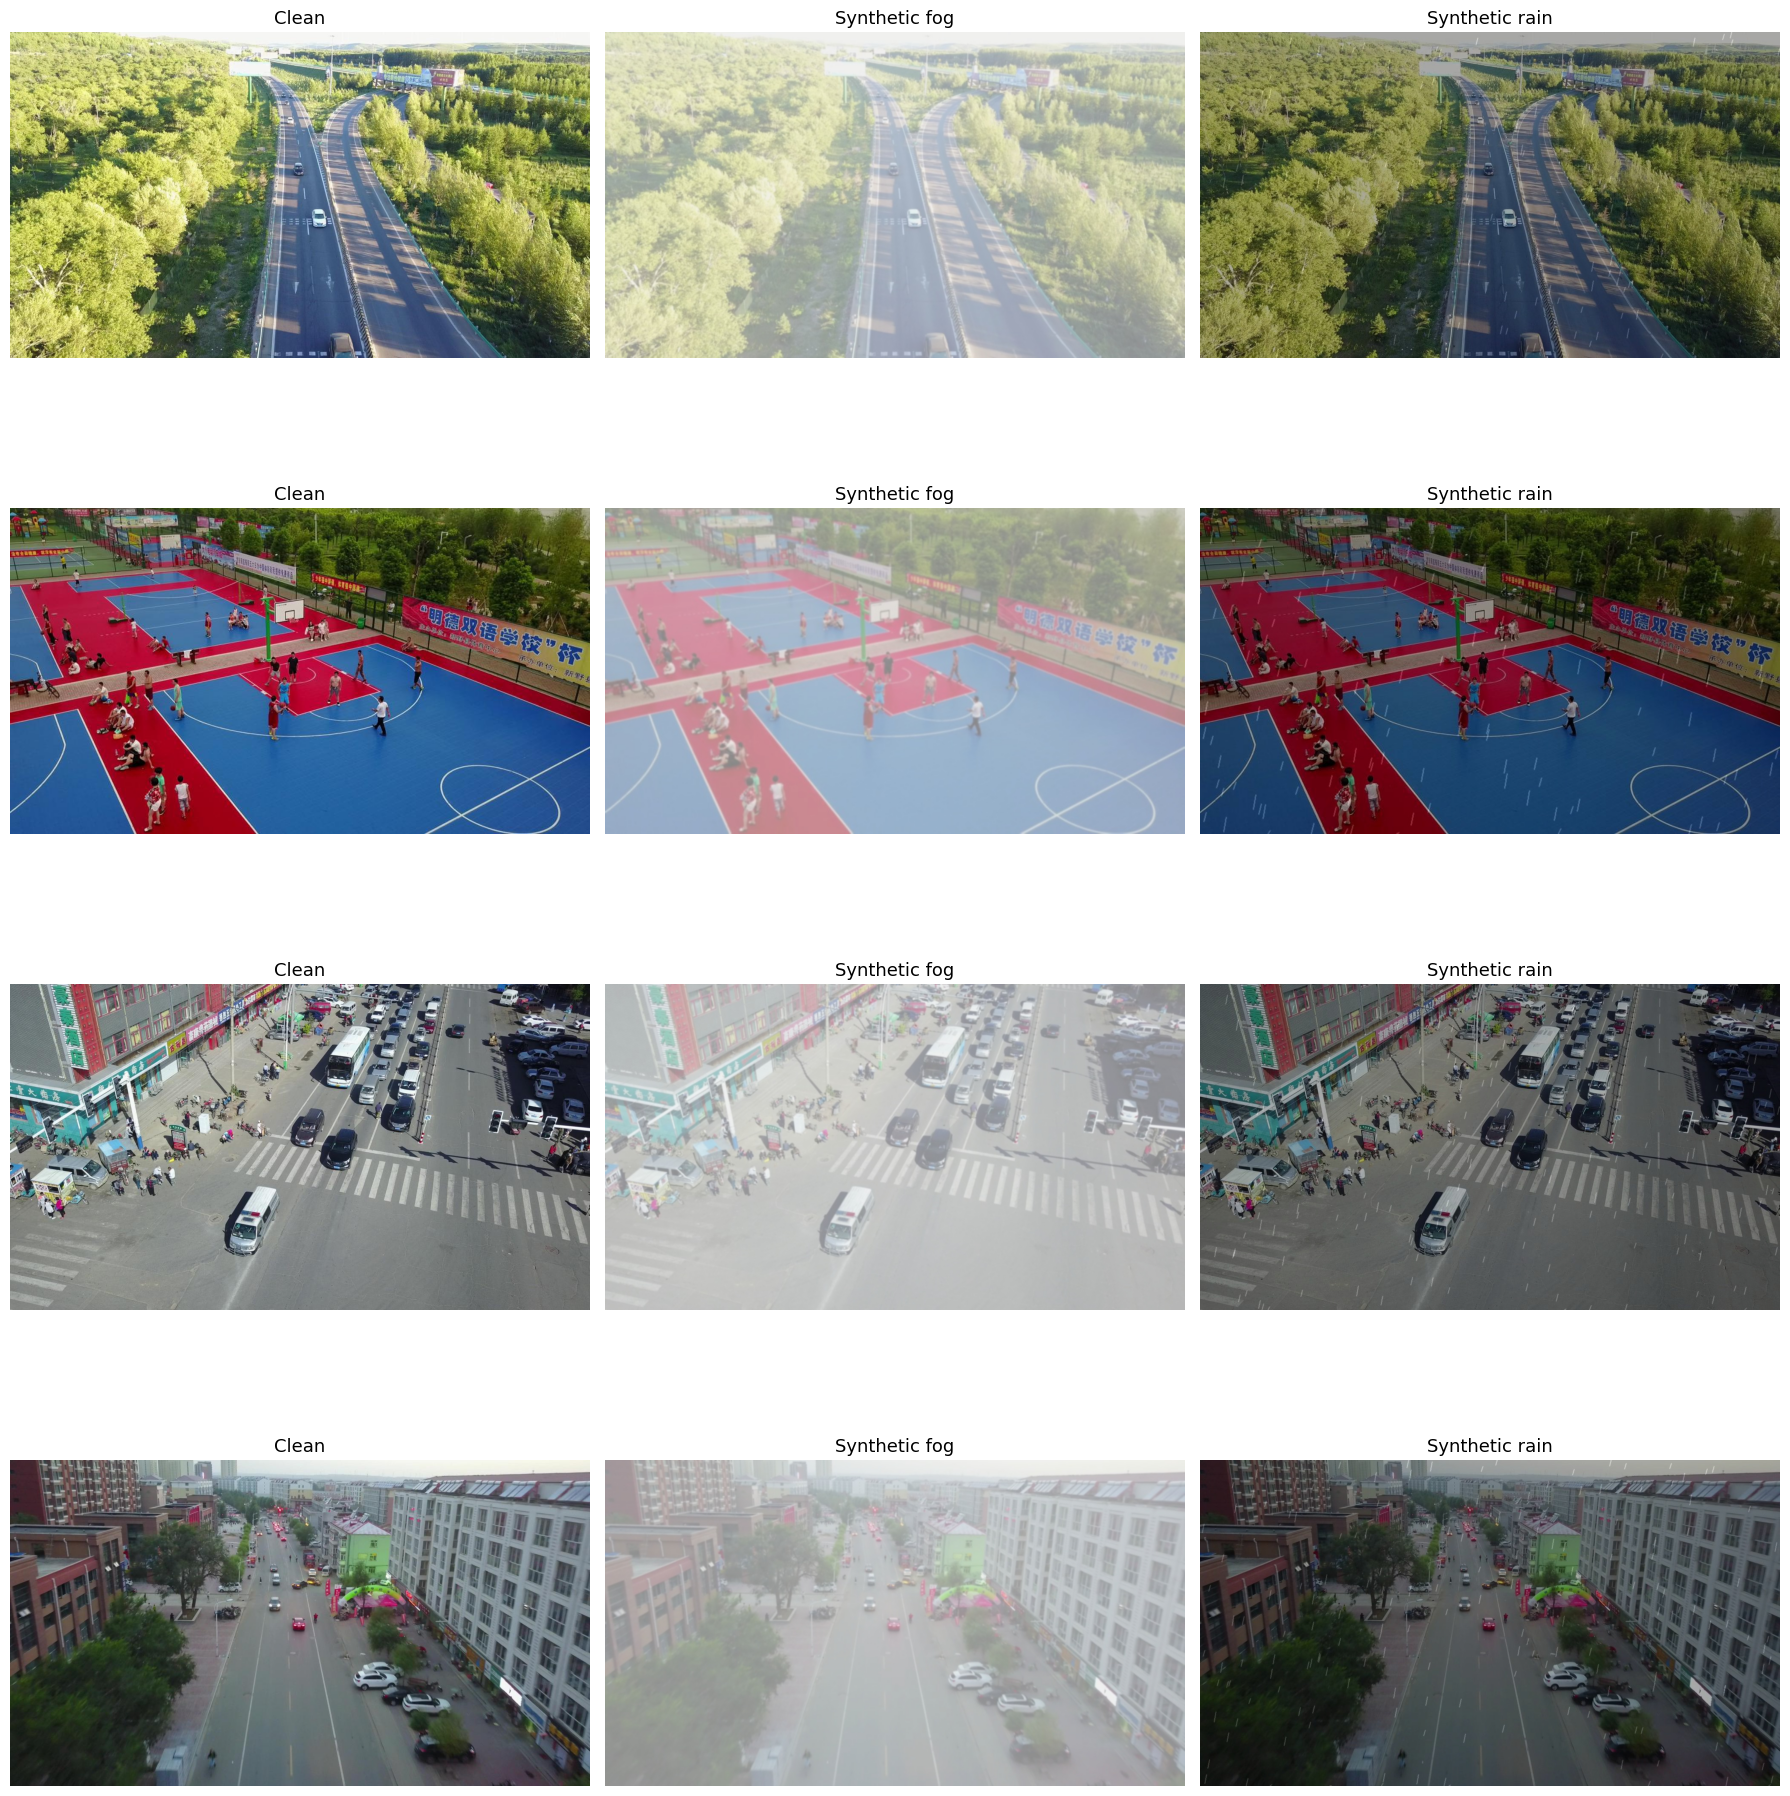

In [17]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

image_paths = sorted(SOURCE_IMG_DIR.glob("*.jpg"))
rng = np.random.default_rng(42)
selected_paths = rng.choice(image_paths, size=4, replace=False)

fig, axes = plt.subplots(4, 3, figsize=(18, 20))

for row, clean_path in enumerate(selected_paths):
    fog_path = WEATHER_ROOT / "fog" / "images/val" / clean_path.name
    rain_path = WEATHER_ROOT / "rain" / "images/val" / clean_path.name

    images = [
        ("Clean", cv2.imread(str(clean_path))),
        ("Synthetic fog", cv2.imread(str(fog_path))),
        ("Synthetic rain", cv2.imread(str(rain_path))),
    ]

    for col, (title, image_bgr) in enumerate(images):
        assert image_bgr is not None, f"无法读取：{title} / {clean_path.name}"

        axes[row, col].imshow(
            cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
        )
        axes[row, col].set_title(title, fontsize=13)
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

In [18]:
CLASS_NAMES = """
names:
  0: pedestrian
  1: people
  2: bicycle
  3: car
  4: van
  5: truck
  6: tricycle
  7: awning-tricycle
  8: bus
  9: motor
""".strip()

for weather in ["fog", "rain"]:
    yaml_path = WEATHER_ROOT / f"{weather}.yaml"

    yaml_path.write_text(
        f"""
path: {WEATHER_ROOT / weather}
train: images/val
val: images/val

{CLASS_NAMES}
""".strip()
    )

    print(yaml_path)

/root/autodl-tmp/shift_aware_uav/data/weather_shift/fog.yaml
/root/autodl-tmp/shift_aware_uav/data/weather_shift/rain.yaml


In [21]:
from ultralytics import YOLO
import pandas as pd

BEST_MODEL = (
    PROJECT_DIR / "runs/visdrone_source_yolo11n/weights/best.pt"
)

model = YOLO(str(BEST_MODEL))

datasets = {
    "clean": PROJECT_DIR / "visdrone.yaml",
    "fog": WEATHER_ROOT / "fog.yaml",
    "rain": WEATHER_ROOT / "rain.yaml",
}

records = []

for name, yaml_file in datasets.items():
    metrics = model.val(
        data=str(yaml_file),
        split="val",
        imgsz=640,
        batch=16,
        device=0,
        workers=8,
        project=str(PROJECT_DIR / "evaluations"),
        name=f"source_model_on_{name}",
        exist_ok=True,
        plots=True,
    )

    records.append({
        "condition": name,
        "precision": metrics.box.mp,
        "recall": metrics.box.mr,
        "mAP50": metrics.box.map50,
        "mAP50_95": metrics.box.map,
    })

results_table = pd.DataFrame(records)
results_table

Ultralytics 8.4.159 🚀 Python-3.10.8 torch-2.7.1+cu118 CUDA:0 (NVIDIA GeForce RTX 3090, 24124MiB)
YOLO11n summary (fused): 100 layers, 2,584,102 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3046.3±352.8 MB/s, size: 281.6 KB)
val: Scanning /root/autodl-tmp/shift_aware_uav/data/visdrone_yolo/labels/val.cache... 548 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 548/548 104.5Mit/s 0.0s
WARNING ⚠️ Dataset images contain up to 317 objects (val=317), but max_det=300. This mismatch can cap recall and produce invalid validation metrics. Raising it may increase validation cost but cannot increase model or export capacity, which may cap recall. Setting max_det=317 to match the observed maximum.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 35/35 10.9it/s 3.2s0.1s
                   all        548      38759      0.432      0.318      0.296      0.167
            pedestrian        520       

,condition,precision,recall,mAP50,mAP50_95
0,clean,0.431838,0.317849,0.295565,0.166680
1,fog,0.367160,0.261391,0.227900,0.127981
2,rain,0.221891,0.103370,0.066862,0.029378
